# Predicting Obesity Levels
This project will use a dataset of various habits and lifestyle choices to predict the obesity levels of various participants.

In [1]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
import phik
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import RandomizedSearchCV
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


# EDA exploring and transforming columns in preparation for modelling

When downloading this dataset i found that there was no missing data in here so this is something I will not have to deal with. However, some of the column names are not clear in what they are showing, while it would be possible to rename these columns, I think when handling the data shorter column names will be useful. I will therefore create a key here for the column names to refer back to throughout the analysis.
FAVC - 	Do you eat high caloric food frequently?
FCVC - Do you usually eat vegetables in your meals?
NCP	- How many main meals do you have daily?
CAEC - Do you eat any food between meals?
CH2O - How much water do you drink daily?
SCC	- Do you monitor the calories you eat daily?
FAF	- How often do you have physical activity?
TUE	- How much time do you use technological devices such as cell phone, videogames, television, computer and others?
CALC - How often do you drink alcohol?
MTRANS - Which transportation do you usually use?

I will transform the binary columns to either booleans or 1/0, and the ordinal columns to numbered columns and then finally for MTRANS i will create dummy columns.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   str    
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   str    
 5   FAVC                            2111 non-null   str    
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   str    
 9   SMOKE                           2111 non-null   str    
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   str    
 12  FAF                             2111 non-null

Converting binary columns to 1 or 0. For columns where to possible answers are yes or no, i will make them booleans. For the Gender column male is 1 and female is 0.

In [4]:
cols = [c for c in df.columns if set(df[c].unique()).issubset({'yes', 'no'})]
df[cols] = df[cols].apply(lambda col: col.map({'yes': True, 'no': False}))
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,True,False,2.0,3.0,Sometimes,False,2.0,False,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,True,False,3.0,3.0,Sometimes,True,3.0,True,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,True,False,2.0,3.0,Sometimes,False,2.0,False,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,False,False,3.0,3.0,Sometimes,False,2.0,False,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,False,False,2.0,1.0,Sometimes,False,2.0,False,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [5]:
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,0,21.0,1.62,64.0,True,False,2.0,3.0,Sometimes,False,2.0,False,0.0,1.0,no,Public_Transportation,Normal_Weight
1,0,21.0,1.52,56.0,True,False,3.0,3.0,Sometimes,True,3.0,True,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,1,23.0,1.80,77.0,True,False,2.0,3.0,Sometimes,False,2.0,False,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,1,27.0,1.80,87.0,False,False,3.0,3.0,Sometimes,False,2.0,False,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,1,22.0,1.78,89.8,False,False,2.0,1.0,Sometimes,False,2.0,False,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [6]:
float_cols = df.select_dtypes(include='float64').columns
df[float_cols].describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


In [7]:
unique_summary = df.select_dtypes(include=['object', 'string']).apply(lambda col: col.unique())
unique_summary

CAEC                        [Sometimes, Frequently, Always, no]
CALC                        [no, Sometimes, Frequently, Always]
MTRANS        [Public_Transportation, Walking, Automobile, M...
NObeyesdad    [Normal_Weight, Overweight_Level_I, Overweight...
dtype: object

Encoding the ordinal columns using the ordinal encoder

In [8]:
encoder = OrdinalEncoder(categories=[['Always','Frequently','Sometimes','no']])
CAEC_reshaped = df['CAEC'].values.reshape(-1,1)
CALC_reshaped = df['CALC'].values.reshape(-1,1)
df['CAEC'] = encoder.fit_transform(CAEC_reshaped)
df['CALC'] = encoder.fit_transform(CALC_reshaped)
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,0,21.0,1.62,64.0,True,False,2.0,3.0,2.0,False,2.0,False,0.0,1.0,3.0,Public_Transportation,Normal_Weight
1,0,21.0,1.52,56.0,True,False,3.0,3.0,2.0,True,3.0,True,3.0,0.0,2.0,Public_Transportation,Normal_Weight
2,1,23.0,1.80,77.0,True,False,2.0,3.0,2.0,False,2.0,False,2.0,1.0,1.0,Public_Transportation,Normal_Weight
3,1,27.0,1.80,87.0,False,False,3.0,3.0,2.0,False,2.0,False,2.0,0.0,1.0,Walking,Overweight_Level_I
4,1,22.0,1.78,89.8,False,False,2.0,1.0,2.0,False,2.0,False,0.0,0.0,2.0,Public_Transportation,Overweight_Level_II


Creating dummy columns for the 

In [9]:
ohe = pd.get_dummies(df['MTRANS'])
df = df.join(ohe)
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,...,FAF,TUE,CALC,MTRANS,NObeyesdad,Automobile,Bike,Motorbike,Public_Transportation,Walking
0,0,21.0,1.62,64.0,True,False,2.0,3.0,2.0,False,...,0.0,1.0,3.0,Public_Transportation,Normal_Weight,False,False,False,True,False
1,0,21.0,1.52,56.0,True,False,3.0,3.0,2.0,True,...,3.0,0.0,2.0,Public_Transportation,Normal_Weight,False,False,False,True,False
2,1,23.0,1.80,77.0,True,False,2.0,3.0,2.0,False,...,2.0,1.0,1.0,Public_Transportation,Normal_Weight,False,False,False,True,False
3,1,27.0,1.80,87.0,False,False,3.0,3.0,2.0,False,...,2.0,0.0,1.0,Walking,Overweight_Level_I,False,False,False,False,True
4,1,22.0,1.78,89.8,False,False,2.0,1.0,2.0,False,...,0.0,0.0,2.0,Public_Transportation,Overweight_Level_II,False,False,False,True,False


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   int64  
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   bool   
 5   FAVC                            2111 non-null   bool   
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   float64
 9   SMOKE                           2111 non-null   bool   
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   bool   
 12  FAF                             2111 non-null

Here I will assess the correlation between the numerical and catergorical variables using pair plots and a heatmap of the correlations. This will inform my feature engineering for modelling.

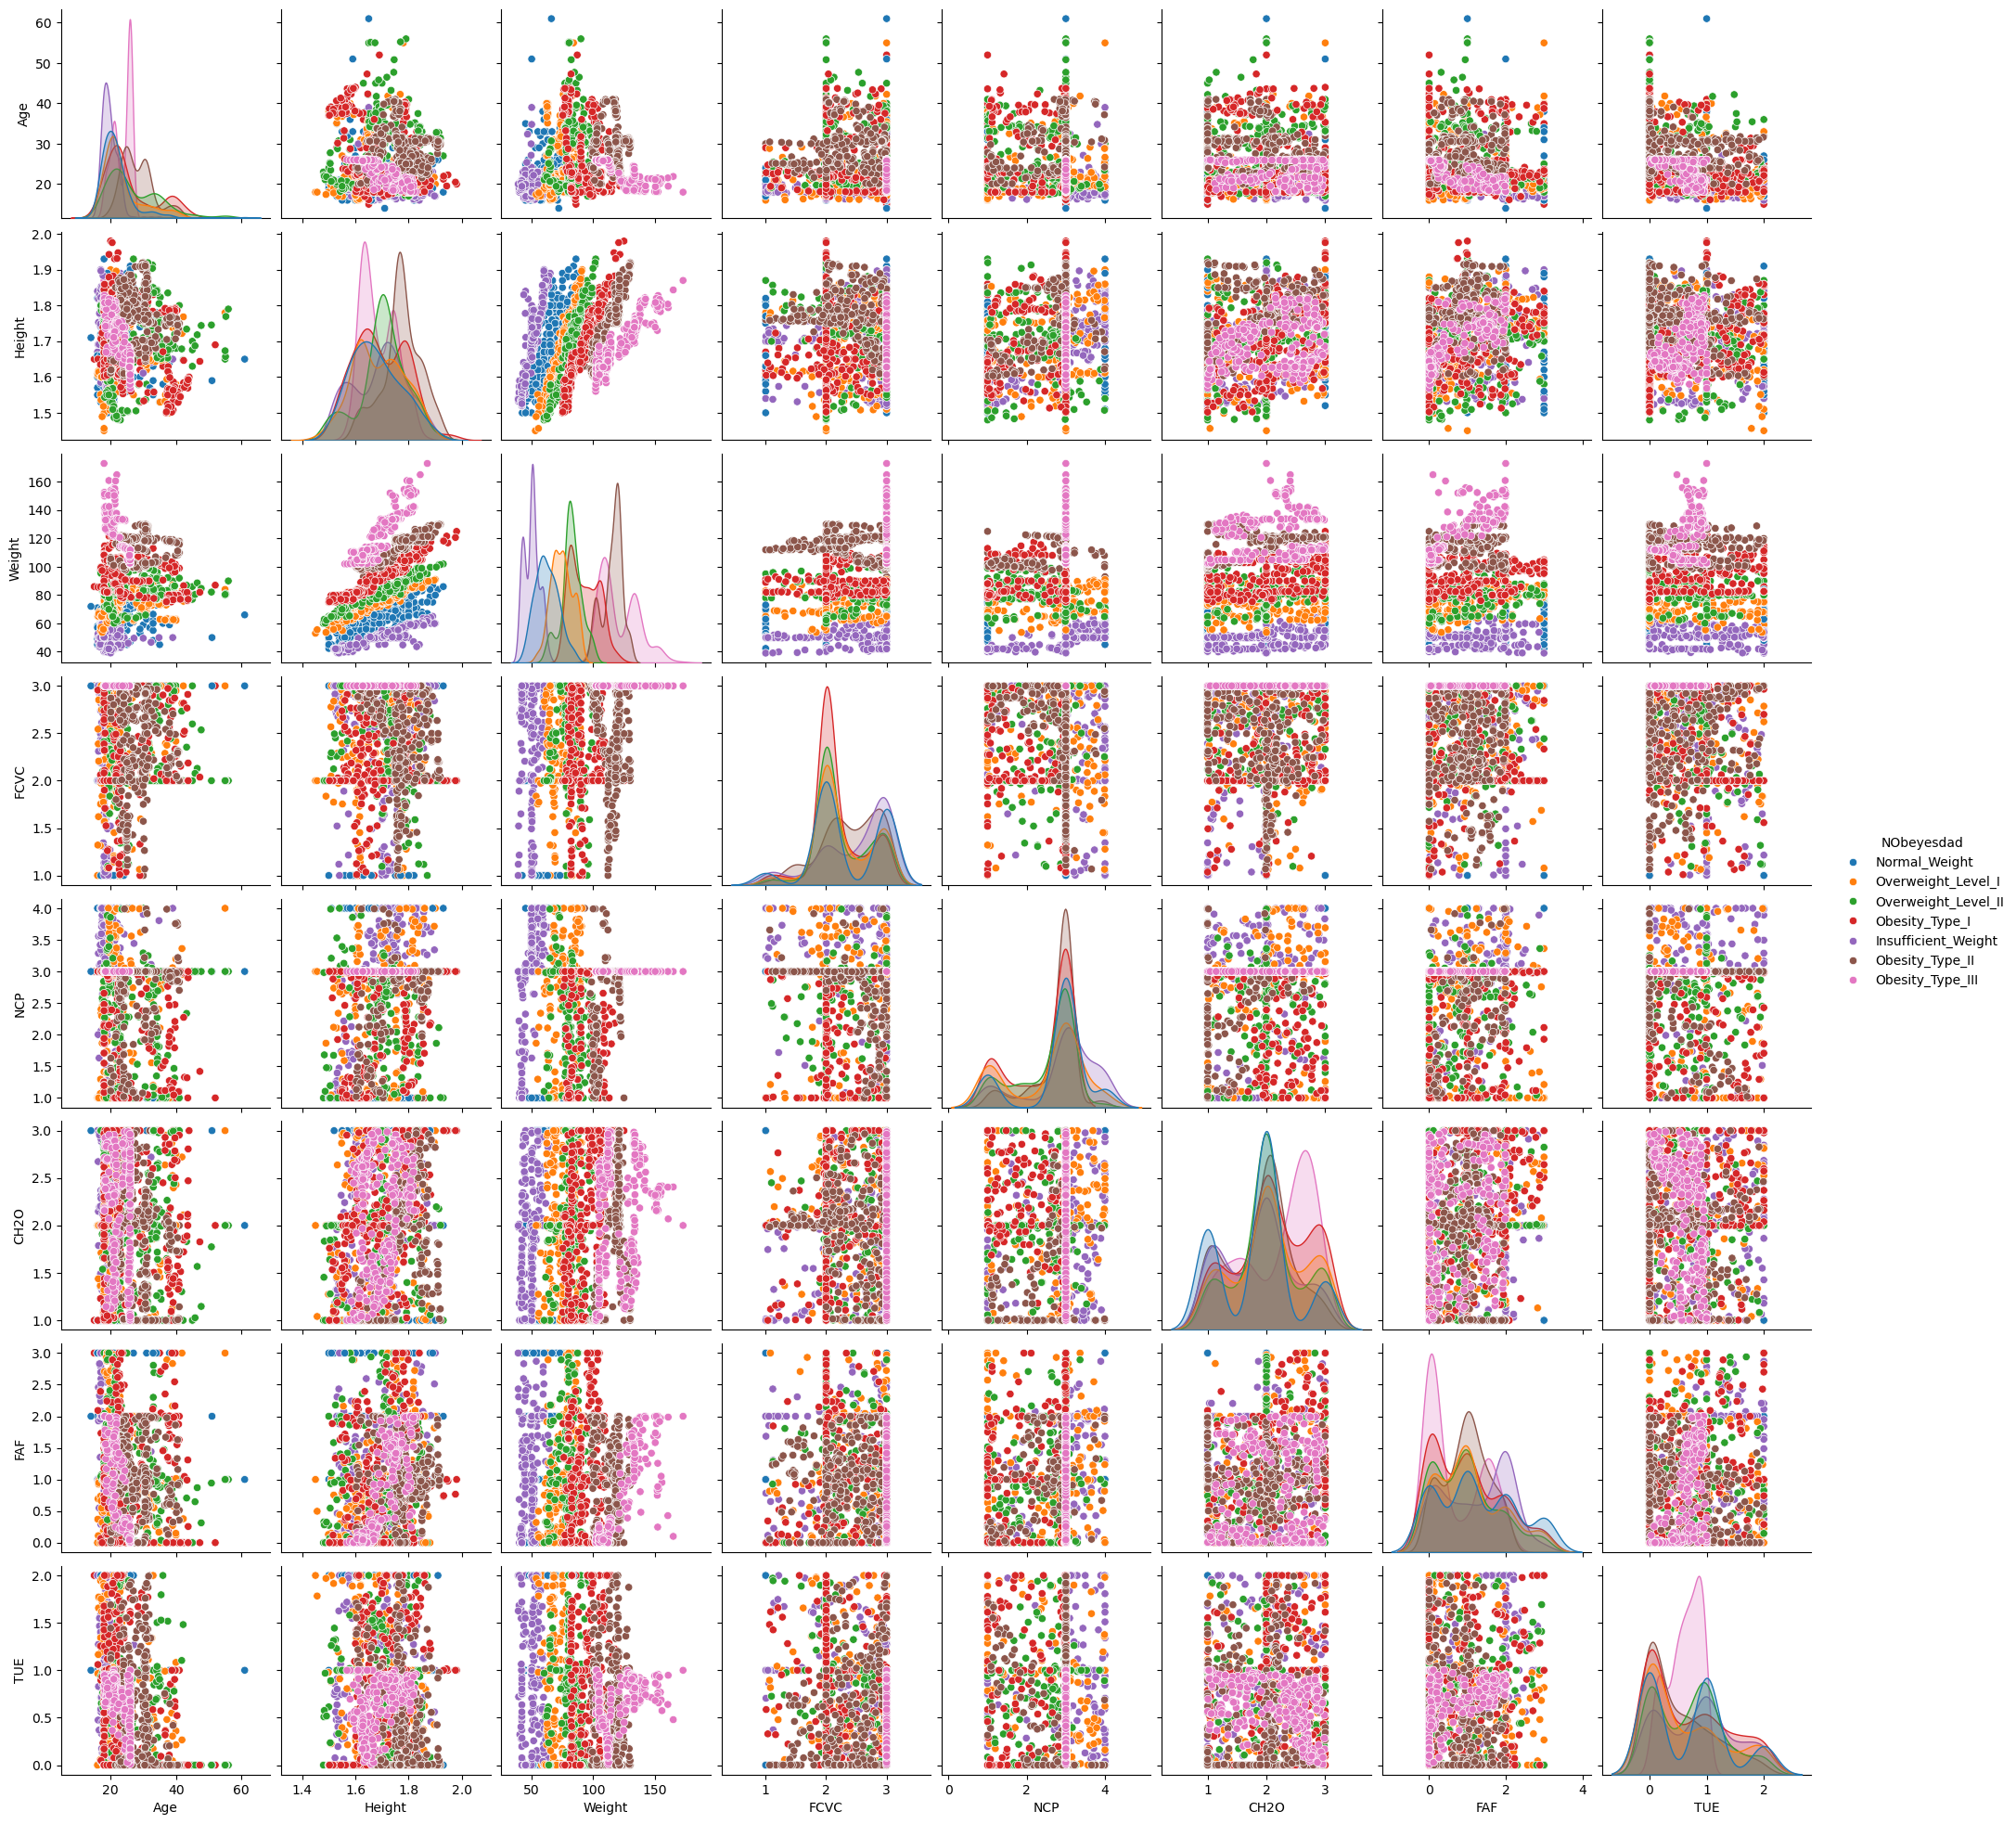

In [11]:
sns.pairplot(df, hue = 'NObeyesdad', vars=['Age','Height','Weight','FCVC','NCP','CH2O','FAF','TUE'])

The pairplots of the numerical columns show some clear separation of obesity categories suggesting that many of these features will be important in the model. Most of the density plots show a broadly normal distribution other than the age category which shows a slight right skew, this will be adjusted for during standardisation.

interval columns not set, guessing: ['Gender', 'Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CAEC', 'CH2O', 'FAF', 'TUE', 'CALC']


<Axes: >

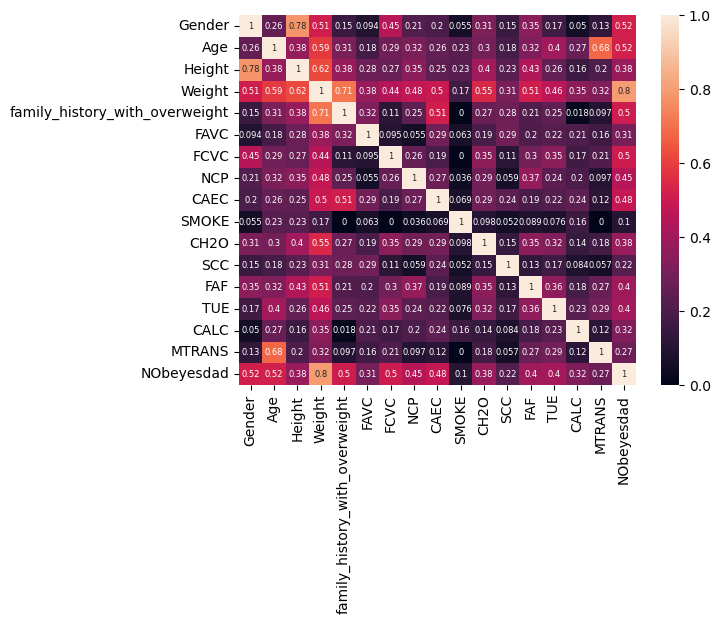

In [12]:
sns.heatmap(df.drop(columns = ['Automobile', 'Bike','Motorbike','Public_Transportation','Walking']).phik_matrix(), annot=True, annot_kws={'size':6})


According to the heatmap of correlations several of the features are highly correlated and therefore some of these features could be dropped from the modeling. I have set a treshold of correlation between features of 0.7, therefore if any features have a correlation of more than 0.7 then one of them will be dropped. To decide which of these is best to drop I will check the correlation of each of these with the target (NObeyesdad) and drop the feature which is least correlated with this.
Therefore it is worth considering dropping Height and Family history with overweight from the final analysis, before dropping nay columns though i will perform an initial test with my 3 models and assess the impact of the features using permutation importance.

First I will split the data into train val and test to use for training the model and hyper parameter tuning before the final test of the model.

In [13]:
X = df.drop(columns = ['NObeyesdad', 'MTRANS'])
y = df['NObeyesdad']
train_ratio = 0.7
validation_ratio = 0.15
test_ratio = 0.15

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=1 - train_ratio)

X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=test_ratio/(test_ratio + validation_ratio))

I will create a pipeline for transforming the age category using a log transformer and then add this into a preprocessor pipeline to stndardise all the other numerical and ordinal columns using standard scaler. finally I will add this pipeline to the model pipeline for my first model which will be linearSVC.

After Linear SVC I will also model using both k nearest neighbour and random tree classifiers and assess which performs the best. For both linear SVC and k nearest neighbour will require the standardisation steps however the random tree model will be able to run on the raw data.

for each model I will asess the accuracy and the importance of all the features to determine if any features are unecessary or adding noise, as well as whih model to take forward to hyper parameter tuning.

In [14]:
skewed_cols = ['Age']
num_and_ordinal_cols = ['Age','Height','Weight','FCVC','NCP','CH2O','FAF','TUE','CAEC','CALC']
binary_and_ohe_cols = ['Gender','family_history_with_overweight','FAVC','SMOKE','SCC','Automobile', 'Bike','Motorbike','Public_Transportation','Walking'] # Leave as 0/1

age_pipeline = Pipeline([
    ('log', FunctionTransformer(np.log1p)),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('age', age_pipeline, skewed_cols),
        ('num', StandardScaler(), num_and_ordinal_cols),
        ('bin', 'passthrough', binary_and_ohe_cols)
    ]
)

model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LinearSVC(max_iter=5000, random_state=42))
])

model_pipeline.fit(X_train, y_train)

y_pred = model_pipeline.predict(X_val)

print(classification_report(y_val, y_pred))

                     precision    recall  f1-score   support

Insufficient_Weight       0.91      0.98      0.94        41
      Normal_Weight       0.84      0.58      0.69        55
     Obesity_Type_I       0.59      0.77      0.67        43
    Obesity_Type_II       0.85      1.00      0.92        44
   Obesity_Type_III       1.00      1.00      1.00        41
 Overweight_Level_I       0.69      0.67      0.68        46
Overweight_Level_II       0.66      0.57      0.61        47

           accuracy                           0.78       317
          macro avg       0.79      0.80      0.79       317
       weighted avg       0.79      0.78      0.78       317



In [15]:
linear_result = permutation_importance(
    model_pipeline, X_val, y_val, n_repeats=10, random_state=42, scoring='f1_macro'
)

importances = pd.Series(linear_result.importances_mean, index=X_test.columns)
print(importances.sort_values(ascending=False).head(10))

Weight                            0.448601
Gender                            0.158114
Height                            0.122134
Age                               0.054123
family_history_with_overweight    0.045328
CAEC                              0.044374
Public_Transportation             0.039655
FAVC                              0.036381
Automobile                        0.033010
CALC                              0.022828
dtype: float64


In [16]:
knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=5, weights='distance'))
])

knn_pipeline.fit(X_train, y_train)
y_pred_knn = knn_pipeline.predict(X_val)

print(classification_report(y_val, y_pred_knn))

                     precision    recall  f1-score   support

Insufficient_Weight       0.72      0.88      0.79        41
      Normal_Weight       0.71      0.31      0.43        55
     Obesity_Type_I       0.85      0.91      0.88        43
    Obesity_Type_II       0.96      0.98      0.97        44
   Obesity_Type_III       1.00      1.00      1.00        41
 Overweight_Level_I       0.70      0.93      0.80        46
Overweight_Level_II       0.80      0.85      0.82        47

           accuracy                           0.82       317
          macro avg       0.82      0.84      0.81       317
       weighted avg       0.81      0.82      0.80       317



In [17]:
knn_result = permutation_importance(
    knn_pipeline, X_val, y_val, n_repeats=10, random_state=42, scoring='f1_macro'
)

importances = pd.Series(knn_result.importances_mean, index=X_test.columns)
print(importances.sort_values(ascending=False).head(10))

Weight    0.200160
Age       0.163346
NCP       0.111363
CALC      0.099297
Height    0.097328
TUE       0.067156
FCVC      0.063822
CAEC      0.059698
FAF       0.047535
CH2O      0.046616
dtype: float64


In [18]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_val)
print(classification_report(y_val, y_pred_rf))

                     precision    recall  f1-score   support

Insufficient_Weight       1.00      0.90      0.95        41
      Normal_Weight       0.87      0.95      0.90        55
     Obesity_Type_I       0.96      1.00      0.98        43
    Obesity_Type_II       0.98      0.98      0.98        44
   Obesity_Type_III       1.00      1.00      1.00        41
 Overweight_Level_I       0.89      0.87      0.88        46
Overweight_Level_II       0.91      0.87      0.89        47

           accuracy                           0.94       317
          macro avg       0.94      0.94      0.94       317
       weighted avg       0.94      0.94      0.94       317



In [19]:
rf_result = permutation_importance(
    rf_model, X_val, y_val, n_repeats=10, random_state=42, scoring='f1_macro'
)

importances = pd.Series(rf_result.importances_mean, index=X_test.columns)
print(importances.sort_values(ascending=False).head(10))

Weight                            0.527690
Height                            0.069760
Age                               0.060951
FCVC                              0.057674
Gender                            0.047575
CAEC                              0.012159
FAVC                              0.005266
NCP                               0.004566
CH2O                              0.003563
family_history_with_overweight    0.003333
dtype: float64


Based on the results above it seems that all features have a role to play and therefore none will be dropped from the model. there is a clear winner in terms of accuracy across the board and this is the random tree classifier. with a total accuracy of 95% there may not be much improvement to be gained from hyper parameter tuning. but as this is a project to assess my knowledge in machine learning pathways I will still perform a randomized search to try and improve the performance.

In [20]:
# 1. Refined parameter space tailored for high-accuracy, fine-grained splits
param_dist = {
    'n_estimators': list((100, 200, 300, 500)),
    'max_depth': [None, 15, 20, 25, 30],
    'min_samples_split': list((2, 3, 5)),
    'min_samples_leaf': list((1, 2)),
    'max_features': ['sqrt', 'log2', None],
    'criterion': ['gini', 'entropy']
}

# 2. Set up RandomizedSearchCV
rf_random = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=40,                 # 40 combinations is plenty for this focused space
    cv=5,                      # 5-fold stratified cross-validation
    scoring='f1_macro',        # Protect your 0.94 macro average across all 7 classes
    n_jobs=-1,                 # Use all CPU cores
    random_state=42,
    verbose=1
)

# 3. Fit ONLY on training data
rf_random.fit(X_train, y_train)

# 4. Evaluate on unseen test data
print("Best Hyperparameters:", rf_random.best_params_)
print("Best CV Macro F1:", round(rf_random.best_score_, 4))

best_rf = rf_random.best_estimator_
y_pred_tuned = best_rf.predict(X_test)
print(classification_report(y_test, y_pred_tuned))

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best Hyperparameters: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': 30, 'criterion': 'entropy'}
Best CV Macro F1: 0.9571
                     precision    recall  f1-score   support

Insufficient_Weight       0.98      0.96      0.97        45
      Normal_Weight       0.93      0.89      0.91        44
     Obesity_Type_I       0.94      0.98      0.96        51
    Obesity_Type_II       1.00      0.97      0.99        40
   Obesity_Type_III       1.00      1.00      1.00        48
 Overweight_Level_I       0.87      0.94      0.91        51
Overweight_Level_II       0.94      0.89      0.92        38

           accuracy                           0.95       317
          macro avg       0.95      0.95      0.95       317
       weighted avg       0.95      0.95      0.95       317



The hyper parameter tuning has shown a slight increase in almost all results, with the exception of the precision of overweight level 1 predictions. Overall though this is definitely an improvement and these hyperparameters will be used in the final model.

Below I have combined the training and validation data and will use this to train the final model before testing on the test data.

=== FINAL TEST SET PERFORMANCE ===
                     precision    recall  f1-score   support

Insufficient_Weight       0.98      0.93      0.95        45
      Normal_Weight       0.93      0.93      0.93        44
     Obesity_Type_I       0.94      0.98      0.96        51
    Obesity_Type_II       1.00      0.97      0.99        40
   Obesity_Type_III       1.00      1.00      1.00        48
 Overweight_Level_I       0.91      0.94      0.92        51
Overweight_Level_II       0.92      0.89      0.91        38

           accuracy                           0.95       317
          macro avg       0.95      0.95      0.95       317
       weighted avg       0.95      0.95      0.95       317



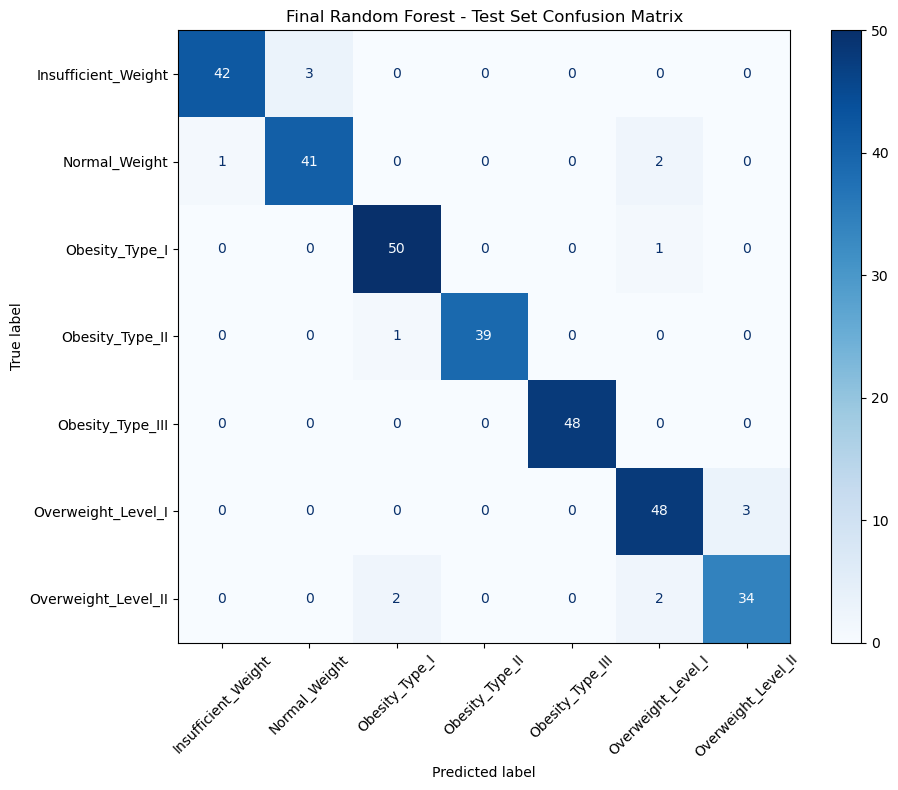

In [21]:
X_train_full = pd.concat([X_train, X_val], axis=0)
y_train_full = pd.concat([y_train, y_val], axis=0)

final_rf = RandomForestClassifier(
    n_estimators=500,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=None,
    max_depth=25,
    criterion='entropy',
    random_state=42,
    n_jobs=-1
)

final_rf.fit(X_train_full, y_train_full)

y_test_pred = final_rf.predict(X_test)

print("=== FINAL TEST SET PERFORMANCE ===")
print(classification_report(y_test, y_test_pred))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_test_pred, 
    xticks_rotation=45, 
    cmap='Blues', 
    ax=ax
)
plt.title("Final Random Forest - Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

I think that the model chosen performs very well will the main issues being right on the boundary of normal weight overweight level 1 and overweight level 2. This is tricky to avoid as these are very tight boundaries.

For future improvements perhaps creating a BMI column to combine the height and weight columns would help to further improve the accuracy.